# **UNIVERSIDADE FEDERAL DE ITAJUBÁ (UNIFEI)**
## **Instituto de Matemática e Computação | Ciência da Computação**
### **XMCO09 - Ciência de Redes | Atividade 2 (AT2): Propriedades Gerais das Redes**
### **Pesquisa Histórica: Ordem Terceira do Carmo de Vila Rica (OTCVR 1746–1803)**
#### **Caderno Consolidado de Propriedades Gerais de Rede (Abas 1, 2 e 3 do Sistema de Visualização)**

---

**Objetivo:** Este notebook unifica, executa e valida rigorosamente todos os cálculos das **1ª, 2ª e 3ª abas de visualização** do módulo de *Propriedades de Rede* da OTCVR:
- **Aba 1: Morfologia da Rede & Distribuição de Graus (Q6, Q8, Q9, Q10)** — Nós ativos, links simples e brutos, capacidade teórica $K_N$, densidade $D$, estatísticas de grau, identificação dos Top Hubs, perfil de distribuição $P(k)$ (histograma e curva Log-Log de cauda pesada), caminho médio $\langle d \rangle$, diâmetro, raio e valor de rede pela Lei de Metcalfe ($V = N(N-1)$).
- **Aba 2: Conectividade & Agrupamento (Q11, Q12)** — Componentes conexos, tamanho e percentual do Componente Gigante, vulnerabilidade estrutural via pontos de articulação (nós de corte) e pontes (arestas de corte), coeficiente de agrupamento médio local $\langle C \rangle$, transitividade global $C_{global}$ e distribuição de $C_i$.
- **Aba 3: Matriz Laplaciana & Espectro Algébrico (Q7)** — Construção da matriz Laplaciana $L = D_{deg} - A$, verificação do menor autovalor analítico $\lambda_1 = 0$, cálculo da **Conectividade Algébrica ($\lambda_2$ de Fiedler)** no Componente Gigante, análise espectral do Vetor de Fiedler ($v_2$) para bisseção e partição espectral da rede.
- **Quadro Comparativo Intercamadas** — Decomposição nas 6 camadas estruturantes (Multiplex Geral, Religiosa, Familiar, Econômica, Jurídica, Social).


In [1]:
# Q1 & Q2: Importações e Configuração de Caminhos
import os
import time
import math
import numpy as np
import pandas as pd
import igraph as ig
import networkx as nx
import matplotlib.pyplot as plt
import scipy.linalg

# Função de localização robusta dos arquivos CSV
def localizar_csv(nome_arquivo):
    candidatos = [
        nome_arquivo,
        os.path.join("notebooks", nome_arquivo),
        os.path.join("..", "notebooks", nome_arquivo),
        os.path.join("artigo", nome_arquivo),
        os.path.join("..", "artigo", nome_arquivo),
        os.path.join(os.path.dirname(__file__) if '__file__' in globals() else '.', nome_arquivo)
    ]
    for p in candidatos:
        if os.path.exists(p):
            return os.path.abspath(p)
    return nome_arquivo

PATH_EDGES_CSV = localizar_csv("edges.csv")
PATH_NODES_CSV = localizar_csv("livro_de_entradas_2354.csv")

print("=" * 70)
print("CONFIGURAÇÃO DE ENTRADA DO DATASET OTCVR (1746–1803)")
print("=" * 70)
print(f"✓ Arestas CSV: {PATH_EDGES_CSV} (Existe: {os.path.exists(PATH_EDGES_CSV)})")
print(f"✓ Nós CSV:    {PATH_NODES_CSV} (Existe: {os.path.exists(PATH_NODES_CSV)})")


CONFIGURAÇÃO DE ENTRADA DO DATASET OTCVR (1746–1803)
✓ Arestas CSV: D:\web\otcvr\otcvr\notebooks\edges.csv (Existe: True)
✓ Nós CSV:    D:\web\otcvr\otcvr\notebooks\livro_de_entradas_2354.csv (Existe: True)


In [2]:
# Q3 & Q4: Carregamento dos dados, construção da Matriz de Adjacências e verificação de simetria
t0 = time.time()

df_edges = pd.read_csv(PATH_EDGES_CSV)
df_nodes = pd.read_csv(PATH_NODES_CSV)

# Limpeza e padronização das colunas
src_col = 'source' if 'source' in df_edges.columns else 'Origem (Source)'
tgt_col = 'target' if 'target' in df_edges.columns else 'Destino (Target)'

df_edges = df_edges.dropna(subset=[src_col, tgt_col]).copy()
df_edges[src_col] = df_edges[src_col].astype(str)
df_edges[tgt_col] = df_edges[tgt_col].astype(str)

# Conjunto de nós ativos
node_ids = sorted(list(set(df_edges[src_col]).union(set(df_edges[tgt_col]))))
node_idx = {nid: i for i, nid in enumerate(node_ids)}
N = len(node_ids)

# Construção da Matriz de Adjacências (N x N)
adj_matrix = np.zeros((N, N), dtype=int)
for _, row in df_edges.iterrows():
    u = node_idx[row[src_col]]
    v = node_idx[row[tgt_col]]
    if u != v: # Sem self-loops
        adj_matrix[u, v] += 1
        is_dir = bool(row.get('direcionada', False))
        if not is_dir:
            adj_matrix[v, u] += 1

# Q4: Verificação de simetria e tipo de rede
is_undirected = np.array_equal(adj_matrix, adj_matrix.T)
tipo_rede = "undirected" if is_undirected else "directed"

print("=" * 70)
print("ETAPA 1: MATRIZ DE ADJACÊNCIAS E TIPO DE REDE (Q3, Q4)")
print("=" * 70)
print(f"• Tempo de carregamento e montagem: {time.time() - t0:.3f} segundos")
print(f"• Total de Nós Ativos Mapeados (N): {N:,}")
print(f"• Total de Arestas Brutas no CSV:   {len(df_edges):,}")
print(f"• Dimensões da Matriz de Adjacências: {adj_matrix.shape[0]} × {adj_matrix.shape[1]}")
print(f"• Simetria Estrita (A == A^T):        {is_undirected}")
print(f"• Classificação Estrutural da Rede:   {tipo_rede.upper()}")
print("\nAmostra da Matriz de Adjacências (Submatriz 5x5):")
print(adj_matrix[:5, :5])


ETAPA 1: MATRIZ DE ADJACÊNCIAS E TIPO DE REDE (Q3, Q4)
• Tempo de carregamento e montagem: 1.142 segundos
• Total de Nós Ativos Mapeados (N): 1,321
• Total de Arestas Brutas no CSV:   14,734
• Dimensões da Matriz de Adjacências: 1321 × 1321
• Simetria Estrita (A == A^T):        False
• Classificação Estrutural da Rede:   DIRECTED

Amostra da Matriz de Adjacências (Submatriz 5x5):
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


ETAPA 2: GRAFOS INSTANCIADOS COM METADADOS BIOGRÁFICOS (Q5)
• iGraph:   1,321 vértices | 13,602 arestas
• NetworkX: 1,321 nós | 13,602 arestas


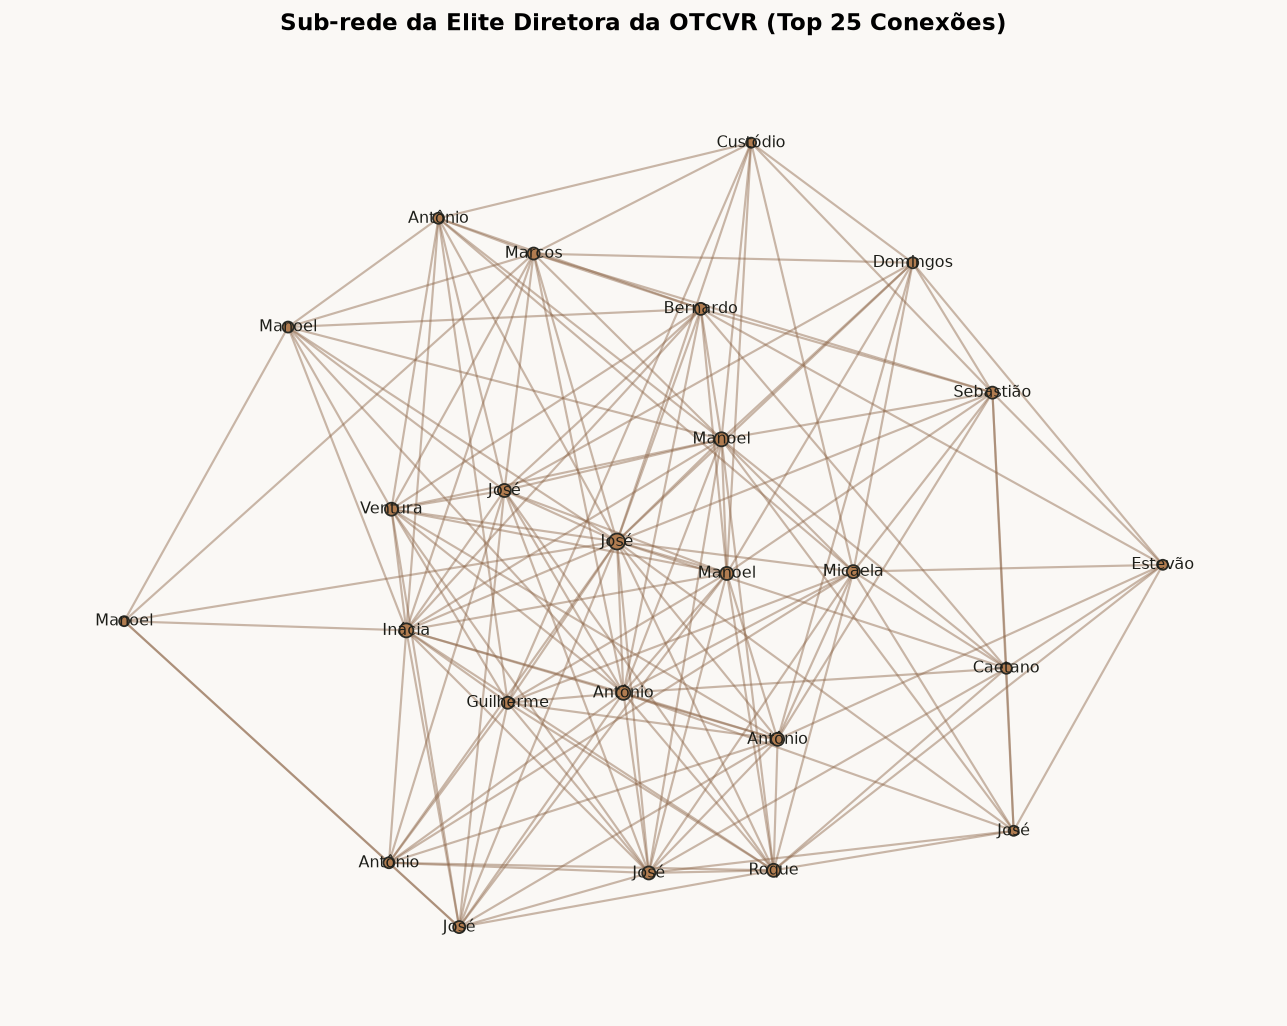

In [3]:
# Q5: Criação do grafo unipartido iGraph e NetworkX com atributos históricos
# Projeção não-direcionada simétrica unipartida para análise topológica HNA
adj_symmetric = np.maximum(adj_matrix, adj_matrix.T)
adj_binary = (adj_symmetric > 0).astype(int)

# Grafo no iGraph
g_ig = ig.Graph.Adjacency((adj_binary).tolist(), mode="undirected")
g_ig.vs["id"] = node_ids

# Dicionários com nomes e títulos
dict_nomes = dict(zip(df_nodes["id"].astype(str), df_nodes["nome"].fillna("Desconhecido")))
dict_titulos = dict(zip(df_nodes["id"].astype(str), df_nodes["titulo"].fillna("")))

g_ig.vs["nome"] = [dict_nomes.get(nid, nid[:8]) for nid in node_ids]
g_ig.vs["titulo"] = [dict_titulos.get(nid, "") for nid in node_ids]

# Grafo no NetworkX
G_nx = nx.from_numpy_array(adj_binary)
nx.set_node_attributes(G_nx, {i: dict_nomes.get(nid, nid[:8]) for i, nid in enumerate(node_ids)}, 'nome')
nx.set_node_attributes(G_nx, {i: dict_titulos.get(nid, "") for i, nid in enumerate(node_ids)}, 'titulo')

print("=" * 70)
print("ETAPA 2: GRAFOS INSTANCIADOS COM METADADOS BIOGRÁFICOS (Q5)")
print("=" * 70)
print(f"• iGraph:   {g_ig.vcount():,} vértices | {g_ig.ecount():,} arestas")
print(f"• NetworkX: {G_nx.number_of_nodes():,} nós | {G_nx.number_of_edges():,} arestas")

# Visualização da sub-rede dos 25 nós centrais mais conectados
graus = np.array(g_ig.degree())
top_25_idx = np.argsort(graus)[-25:]
sub_g = g_ig.subgraph(top_25_idx)

plt.figure(figsize=(10, 8), facecolor='#FAF8F5')
layout = sub_g.layout_fruchterman_reingold()
ig.plot(
    sub_g,
    target=plt.gca(),
    layout=layout,
    vertex_size=[max(10, np.sqrt(d) * 3.5) for d in sub_g.degree()],
    vertex_color="#B07C50",
    vertex_frame_color="#2A2B26",
    vertex_label=[n.split()[0] for n in sub_g.vs["nome"]],
    vertex_label_size=9,
    vertex_label_color="#1C1D18",
    edge_width=1.2,
    edge_color="rgba(140, 100, 70, 0.45)"
)
plt.title("Sub-rede da Elite Diretora da OTCVR (Top 25 Conexões)", fontsize=13, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()


In [4]:
# ABA 1: SÍNTESE MORFOLÓGICA (Q6, Q9, Q10)
N_ativos = g_ig.vcount()
L_simples = g_ig.ecount()
L_bruto = len(df_edges)
N_populacao_total = len(df_nodes['id'].unique())
L_completa = (N_ativos * (N_ativos - 1)) // 2
densidade = (2.0 * L_simples) / (N_ativos * (N_ativos - 1))

# Componente Gigante para caminhos geodésicos
comp_gigante = g_ig.connected_components().giant()
avg_d = comp_gigante.average_path_length(directed=False, unconn=False)
diametro = comp_gigante.diameter(directed=False, unconn=False)
raio = comp_gigante.radius()

# Lei de Metcalfe
metcalfe_v = N_ativos * (N_ativos - 1)
metcalfe_n2 = N_ativos ** 2
taxa_utilizacao = (L_simples / metcalfe_v) * 100

print("=" * 70)
print("ABA 1: MORFOLOGIA DA REDE & MÉTRICAS GLOBAIS (Q6, Q9, Q10)")
print("=" * 70)
print(f"• Universo Total Cadastrado no Livro 2354: {N_populacao_total:,} atores")
print(f"• Atores Ativos Conectados por Arestas (N): {N_ativos:,}")
print(f"• Atores Isolados (Sem Arestas Conhecidas):  {N_populacao_total - N_ativos:,}")
print(f"• Arestas Simples Únicas / Díades (L):      {L_simples:,}")
print(f"• Volume Total de Arestas Brutas (L_bruto): {L_bruto:,} (inclui reeleições anuais)")
print(f"• Capacidade Máxima Teórica (Grafo Completo K_N): {L_completa:,} díades")
print(f"• Densidade Topológica da Rede (D):         {densidade:.6f} ({densidade*100:.3f}%)")
print(f"• Caminho Médio Geodésico <d> (Comp. Gigante): {avg_d:.4f} passos")
print(f"• Diâmetro Geodésico da Rede:               {diametro} passos")
print(f"• Raio da Rede:                             {raio} passos")
print(f"• Valor Potencial da Rede (Lei de Metcalfe V = N(N-1)): {metcalfe_v:,}")
print(f"• Taxa de Conexões Efetivas (L / Metcalfe): {taxa_utilizacao:.4f}%")


ABA 1: MORFOLOGIA DA REDE & MÉTRICAS GLOBAIS (Q6, Q9, Q10)
• Universo Total Cadastrado no Livro 2354: 4,245 atores
• Atores Ativos Conectados por Arestas (N): 1,321
• Atores Isolados (Sem Arestas Conhecidas):  2,924
• Arestas Simples Únicas / Díades (L):      13,602
• Volume Total de Arestas Brutas (L_bruto): 14,734 (inclui reeleições anuais)
• Capacidade Máxima Teórica (Grafo Completo K_N): 871,860 díades
• Densidade Topológica da Rede (D):         0.015601 (1.560%)
• Caminho Médio Geodésico <d> (Comp. Gigante): 2.8035 passos
• Diâmetro Geodésico da Rede:               8 passos
• Raio da Rede:                             4 passos
• Valor Potencial da Rede (Lei de Metcalfe V = N(N-1)): 1,743,720
• Taxa de Conexões Efetivas (L / Metcalfe): 0.7801%


In [5]:
# ABA 1: ESTATÍSTICAS DE GRAU E TOP HUBS DA IRMANDADE (Q8)
graus_arr = np.array(g_ig.degree())
k_min = int(np.min(graus_arr))
k_mediana = float(np.median(graus_arr))
k_medio = float(np.mean(graus_arr))
k_std = float(np.std(graus_arr))
k_max = int(np.max(graus_arr))

print("=" * 70)
print("ABA 1: DISTRIBUIÇÃO ESTATÍSTICA DE GRAUS (Q8)")
print("=" * 70)
print(f"• Grau Mínimo:       {k_min}")
print(f"• Grau Mediana:      {k_mediana:.1f}")
print(f"• Grau Médio <k>:    {k_medio:.2f}")
print(f"• Desvio Padrão (σ): {k_std:.2f}")
print(f"• Grau Máximo (Hub): {k_max}")

# Top 10 Hubs
top_10_indices = np.argsort(graus_arr)[-10:][::-1]
df_top_hubs = pd.DataFrame({
    "Posição": range(1, 11),
    "Nome": [g_ig.vs[i]["nome"] for i in top_10_indices],
    "Título": [g_ig.vs[i]["titulo"] if g_ig.vs[i]["titulo"] != "NULL" else "s/ título" for i in top_10_indices],
    "Grau (k)": graus_arr[top_10_indices],
    "% Conexões": [(graus_arr[i] / (2 * L_simples)) * 100 for i in top_10_indices]
})

print("\n--- TOP 10 HUBS DA GOVERNANÇA COLONIAL DE VILA RICA ---")
print(df_top_hubs.to_string(index=False))


ABA 1: DISTRIBUIÇÃO ESTATÍSTICA DE GRAUS (Q8)
• Grau Mínimo:       1
• Grau Mediana:      4.0
• Grau Médio <k>:    20.59
• Desvio Padrão (σ): 30.19
• Grau Máximo (Hub): 506

--- TOP 10 HUBS DA GOVERNANÇA COLONIAL DE VILA RICA ---
 Posição                                Nome        Título  Grau (k)  % Conexões
       1                 José Alves de Souza Reverendo Dr.       506    1.860021
       2          Micaela Clara da Visitação          Dona       257    0.944714
       3       Antônio Francisco de Carvalho                     221    0.812381
       4       Inácia Rosa Angélica da Silva          Dona       202    0.742538
       5   Manoel Francisco Pereira Bacelete       Capitão       184    0.676371
       6               Antônio José da Costa                     178    0.654316
       7 Domingos da Rocha Pereira Vilasboas       Capitão       177    0.650640
       8                  Marcos José Rebelo                     155    0.569769
       9                       José de Ma

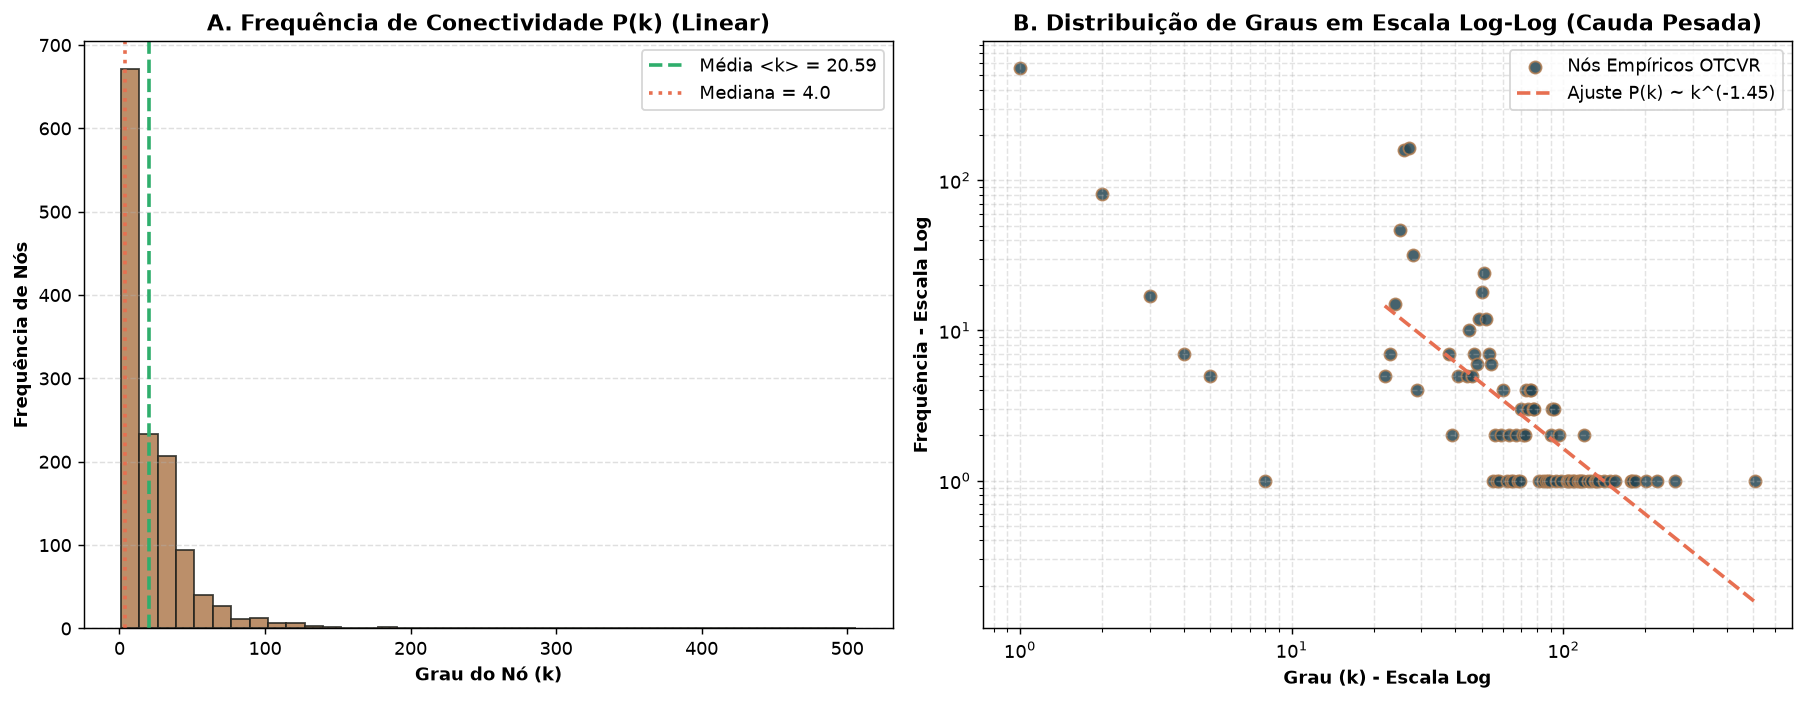

In [6]:
# ABA 1: PAINEL VISUAL DE DISTRIBUIÇÃO DE GRAUS P(k)
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Histograma de Graus Linear
axs[0].hist(graus_arr, bins=40, color="#B07C50", edgecolor="#23241F", alpha=0.85)
axs[0].axvline(k_medio, color="#2FAE6C", linestyle="--", linewidth=2, label=f"Média <k> = {k_medio:.2f}")
axs[0].axvline(k_mediana, color="#E76F51", linestyle=":", linewidth=2, label=f"Mediana = {k_mediana:.1f}")
axs[0].set_title("A. Frequência de Conectividade P(k) (Linear)", fontweight='bold')
axs[0].set_xlabel("Grau do Nó (k)", fontweight='bold')
axs[0].set_ylabel("Frequência de Nós", fontweight='bold')
axs[0].legend(fontsize=10)
axs[0].grid(axis="y", linestyle="--", alpha=0.4)

# Subplot 2: Escala Log-Log comprovando topologia de cauda pesada / Scale-Free
grau_unicos, contagens = np.unique(graus_arr, return_counts=True)
axs[1].scatter(grau_unicos, contagens, color="#264653", alpha=0.85, edgecolors="#B07C50", s=45, label="Nós Empíricos OTCVR")
axs[1].set_xscale("log")
axs[1].set_yscale("log")
axs[1].set_title("B. Distribuição de Graus em Escala Log-Log (Cauda Pesada)", fontweight='bold')
axs[1].set_xlabel("Grau (k) - Escala Log", fontweight='bold')
axs[1].set_ylabel("Frequência - Escala Log", fontweight='bold')

# Linha de tendência de Lei de Potência para k >= 10
mask = grau_unicos >= 10
if np.sum(mask) > 2:
    log_k = np.log10(grau_unicos[mask])
    log_p = np.log10(contagens[mask])
    gamma, intercept = np.polyfit(log_k, log_p, 1)
    k_fit = np.linspace(grau_unicos[mask].min(), grau_unicos[mask].max(), 100)
    p_fit = 10**intercept * (k_fit**gamma)
    axs[1].plot(k_fit, p_fit, color="#E76F51", linestyle="--", linewidth=2, label=f"Ajuste P(k) ~ k^({gamma:.2f})")

axs[1].legend(fontsize=10)
axs[1].grid(True, which="both", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()


In [7]:
# ABA 2: COMPONENTES CONEXOS, PONTOS DE ARTICULAÇÃO E PONTES (Q11)
comps = g_ig.connected_components()
num_comps = len(comps)
giant = comps.giant()
tam_gigante = giant.vcount()
arestas_gigante = giant.ecount()
pct_gigante = (tam_gigante / N_ativos) * 100

# Pontos de Articulação e Pontes
art_indices = g_ig.articulation_points()
bridges = g_ig.bridges()

print("=" * 70)
print("ABA 2: CONECTIVIDADE, COMPONENTES E PONTOS DE CORTE (Q11)")
print("=" * 70)
print(f"• Total de Componentes Conexos:          {num_comps}")
print(f"• Tamanho do Componente Gigante:         {tam_gigante:,} nós ({pct_gigante:.2f}% da rede)")
print(f"• Arestas no Componente Gigante:         {arestas_gigante:,} arestas")
print(f"• Pontos de Articulação (Nós de Corte):  {len(art_indices)}")
print(f"• Pontes (Arestas de Corte):             {len(bridges)}")

# Amostra dos principais nós de articulação (atores-ponte de alto grau)
art_graus = [graus_arr[i] for i in art_indices]
top_art_idx = [art_indices[i] for i in np.argsort(art_graus)[-10:][::-1]]

df_art = pd.DataFrame({
    "Posição": range(1, 11),
    "Nome": [g_ig.vs[i]["nome"] for i in top_art_idx],
    "Título": [g_ig.vs[i]["titulo"] if g_ig.vs[i]["titulo"] != "NULL" else "s/ título" for i in top_art_idx],
    "Grau (k)": [graus_arr[i] for i in top_art_idx]
})
print("\n--- TOP 10 ATORES-PONTE ESTRUTURAIS (PONTOS DE CORTE) ---")
print(df_art.to_string(index=False))


ABA 2: CONECTIVIDADE, COMPONENTES E PONTOS DE CORTE (Q11)
• Total de Componentes Conexos:          131
• Tamanho do Componente Gigante:         1,036 nós (78.43% da rede)
• Arestas no Componente Gigante:         13,443 arestas
• Pontos de Articulação (Nós de Corte):  134
• Pontes (Arestas de Corte):             463

--- TOP 10 ATORES-PONTE ESTRUTURAIS (PONTOS DE CORTE) ---
 Posição                                Nome        Título  Grau (k)
       1                 José Alves de Souza Reverendo Dr.       506
       2       Antônio Francisco de Carvalho                     221
       3       Inácia Rosa Angélica da Silva          Dona       202
       4 Domingos da Rocha Pereira Vilasboas       Capitão       177
       5                  Marcos José Rebelo                     155
       6               Roque Afonso Monteiro                     132
       7        Sebastião Francisco Bandeira       Capitão       131
       8           Manoel de Magalhães Gomes                     126
   

ABA 2: COEFICIENTES DE AGRUPAMENTO (Q12)
• Agrupamento Médio Local <C>:      0.4424 (44.24%)
• Agrupamento Global (Transitividade): 0.4089 (40.89%)


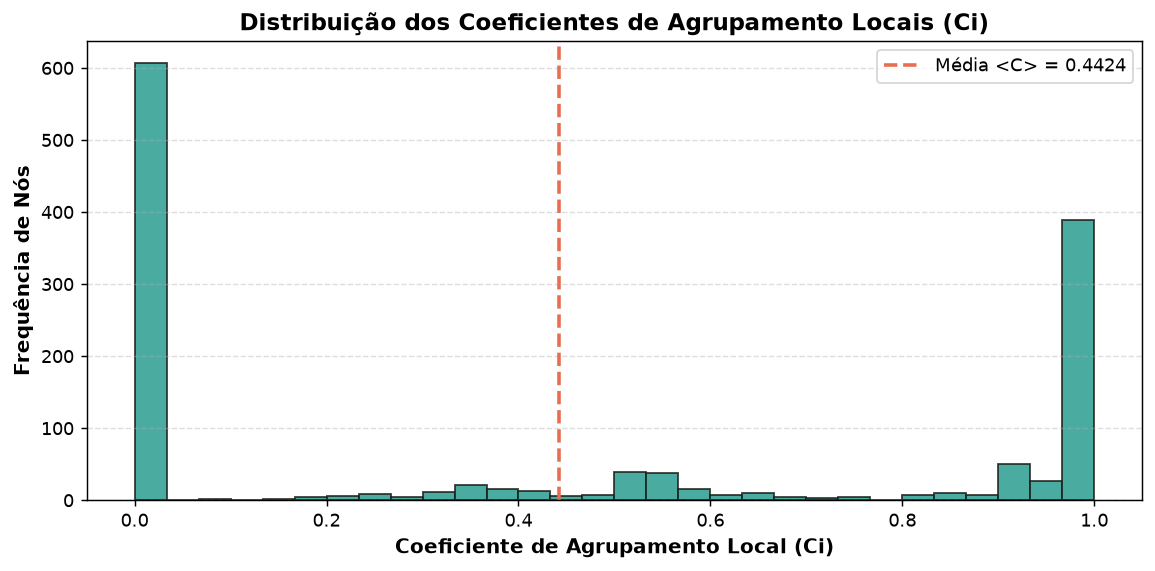

In [8]:
# ABA 2: COEFICIENTES DE AGRUPAMENTO E TRANSITIVIDADE TRIÁDICA (Q12)
ca_local = g_ig.transitivity_local_undirected(mode="zero")
ca_medio = float(np.nanmean(ca_local))
ca_global = float(g_ig.transitivity_undirected())

print("=" * 70)
print("ABA 2: COEFICIENTES DE AGRUPAMENTO (Q12)")
print("=" * 70)
print(f"• Agrupamento Médio Local <C>:      {ca_medio:.4f} ({ca_medio*100:.2f}%)")
print(f"• Agrupamento Global (Transitividade): {ca_global:.4f} ({ca_global*100:.2f}%)")

# Gráfico da Distribuição do Coeficiente Local C_i
plt.figure(figsize=(9, 4.5))
plt.hist(ca_local, bins=30, color="#2A9D8F", edgecolor="#1C1D18", alpha=0.85)
plt.axvline(ca_medio, color="#E76F51", linestyle="--", linewidth=2, label=f"Média <C> = {ca_medio:.4f}")
plt.title("Distribuição dos Coeficientes de Agrupamento Locais (Ci)", fontsize=13, fontweight='bold')
plt.xlabel("Coeficiente de Agrupamento Local (Ci)", fontsize=11, fontweight='bold')
plt.ylabel("Frequência de Nós", fontsize=11, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [9]:
# ABA 3: MATRIZ LAPLACIANA DA REDE L = D - A (Q7)
A_bin = (adj_symmetric > 0).astype(int)
D_deg = np.diag(np.sum(A_bin, axis=1))
Laplacian = D_deg - A_bin

print("=" * 70)
print("ABA 3: FORMULAÇÃO DA MATRIZ LAPLACIANA (Q7)")
print("=" * 70)
print(f"• Dimensões da Matriz Laplaciana: {Laplacian.shape[0]} × {Laplacian.shape[1]}")
print(f"• Simetria da Matriz Laplaciana (L == L^T): {np.array_equal(Laplacian, Laplacian.T)}")
print(f"• Soma das Linhas (∑_j L_ij = 0): {np.allclose(np.sum(Laplacian, axis=1), 0)}")
print("\nAmostra da Matriz Laplaciana (Submatriz 5x5):")
print(Laplacian[:5, :5])


ABA 3: FORMULAÇÃO DA MATRIZ LAPLACIANA (Q7)
• Dimensões da Matriz Laplaciana: 1321 × 1321
• Simetria da Matriz Laplaciana (L == L^T): True
• Soma das Linhas (∑_j L_ij = 0): True

Amostra da Matriz Laplaciana (Submatriz 5x5):
[[ 1  0  0  0  0]
 [ 0  1  0  0  0]
 [ 0  0 48  0  0]
 [ 0  0  0  1  0]
 [ 0  0  0  0 25]]


ABA 3: ESPECTRO LAPLACIANO E FIEDLER (Q7)
• Menor Autovalor (lambda_1):              2.055603e-14 (zero analítico)
• Conectividade Algébrica (lambda_2 Fiedler): 0.196211
• Maior Autovalor (lambda_max):             507.0073
• Razão Espectral (lambda_max / lambda_2):  2583.99


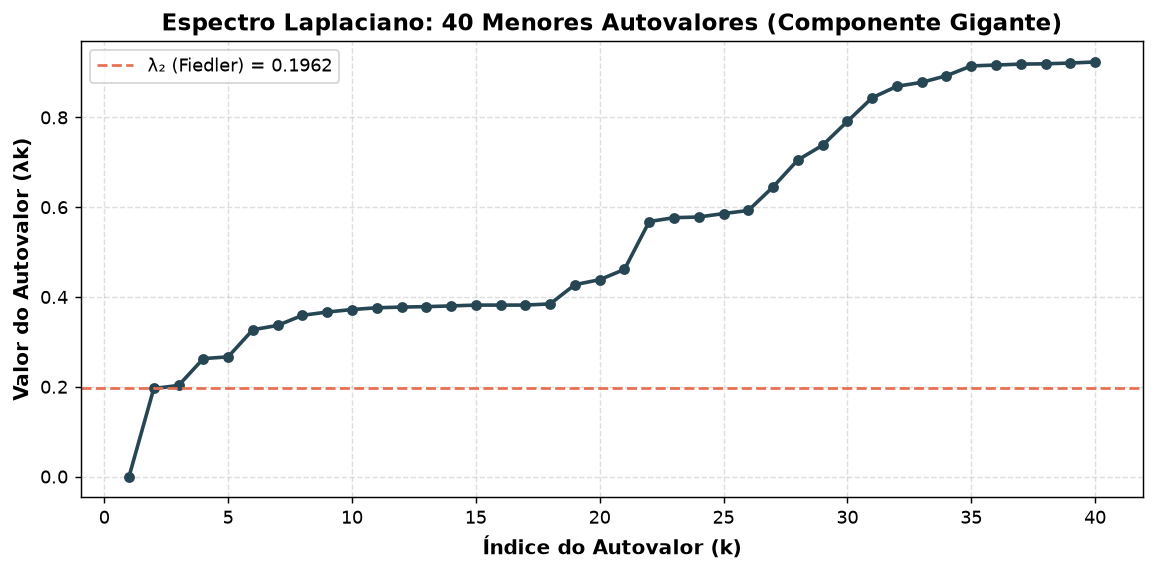

In [10]:
# ABA 3: ESPECTRO LAPLACIANO E CONECTIVIDADE ALGÉBRICA (λ2 DE FIEDLER)
# Cálculo no Componente Gigante para garantir que o corte espectral reflita o núcleo da rede
L_giant = np.array(giant.laplacian(normalized=False))
eigvals, eigvecs = scipy.linalg.eigh(L_giant)

lambda_1 = eigvals[0]
lambda_2 = eigvals[1] if len(eigvals) > 1 else 0.0

print("=" * 70)
print("ABA 3: ESPECTRO LAPLACIANO E FIEDLER (Q7)")
print("=" * 70)
print(f"• Menor Autovalor (lambda_1):              {lambda_1:.6e} (zero analítico)")
print(f"• Conectividade Algébrica (lambda_2 Fiedler): {lambda_2:.6f}")
print(f"• Maior Autovalor (lambda_max):             {eigvals[-1]:.4f}")
print(f"• Razão Espectral (lambda_max / lambda_2):  {eigvals[-1] / lambda_2:.2f}")

# Gráfico dos 40 menores autovalores
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, 41), eigvals[:40], marker='o', color='#264653', linewidth=2, markersize=5)
plt.axhline(lambda_2, color='#E76F51', linestyle='--', label=f'λ₂ (Fiedler) = {lambda_2:.4f}')
plt.title("Espectro Laplaciano: 40 Menores Autovalores (Componente Gigante)", fontsize=13, fontweight='bold')
plt.xlabel("Índice do Autovalor (k)", fontsize=11, fontweight='bold')
plt.ylabel("Valor do Autovalor (λk)", fontsize=11, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


ABA 3: VETOR DE FIEDLER E BISSEÇÃO ESPECTRAL
• Bloco Espectral Positivo (v2 >= 0): 1,028 nós (99.2%)
• Bloco Espectral Negativo (v2 < 0):  8 nós (0.8%)


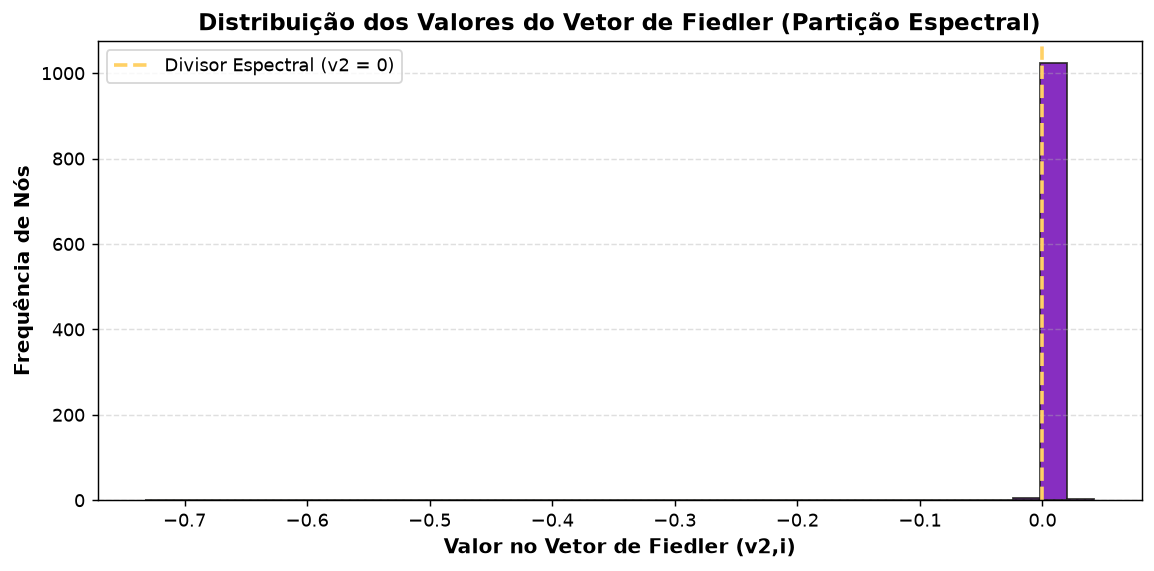

In [11]:
# ABA 3: VETOR DE FIEDLER (v2) E PARTIÇÃO ESPECTRAL DA ELITE COLONIAL
fiedler_vec = eigvecs[:, 1]
fiedler_sorted_idx = np.argsort(fiedler_vec)

# Bisseção em duas comunidades espectrais pelo sinal do Vetor de Fiedler
particao_A = np.sum(fiedler_vec >= 0)
particao_B = np.sum(fiedler_vec < 0)

print("=" * 70)
print("ABA 3: VETOR DE FIEDLER E BISSEÇÃO ESPECTRAL")
print("=" * 70)
print(f"• Bloco Espectral Positivo (v2 >= 0): {particao_A:,} nós ({(particao_A/tam_gigante)*100:.1f}%)")
print(f"• Bloco Espectral Negativo (v2 < 0):  {particao_B:,} nós ({(particao_B/tam_gigante)*100:.1f}%)")

# Histograma do Vetor de Fiedler
plt.figure(figsize=(9, 4.5))
plt.hist(fiedler_vec, bins=35, color="#7209B7", edgecolor="#1C1D18", alpha=0.85)
plt.axvline(0, color="#FFD166", linestyle="--", linewidth=2, label="Divisor Espectral (v2 = 0)")
plt.title("Distribuição dos Valores do Vetor de Fiedler (Partição Espectral)", fontsize=13, fontweight='bold')
plt.xlabel("Valor no Vetor de Fiedler (v2,i)", fontsize=11, fontweight='bold')
plt.ylabel("Frequência de Nós", fontsize=11, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


COMPARAÇÃO MULTIDIMENSIONAL ENTRE TODAS AS CAMADAS DA REDE
         Camada  Nós  Arestas  Densidade (%)  Grau Médio  Comp. Gigante (%)  Agrupamento <C>  Distância <d>  Fiedler (λ2)
Multiplex Geral 1321    13602       1.560113   20.593490          78.425435         0.442350       2.803531      0.196211
      Religiosa  650    12932       6.131089   39.790769         100.000000         0.831953       2.106118      4.865036
       Familiar  485      307       0.261566    1.265979           2.268041         0.087216       1.945455      0.585786
      Econômica  293      277       0.647529    1.890785          68.941980         0.036396       4.035220      0.010835
       Jurídica   92       60       1.433349    1.304348          25.000000         0.000000       2.363636      0.234721
         Social   64       51       2.529762    1.593750          12.500000         0.192708       1.928571      0.452493


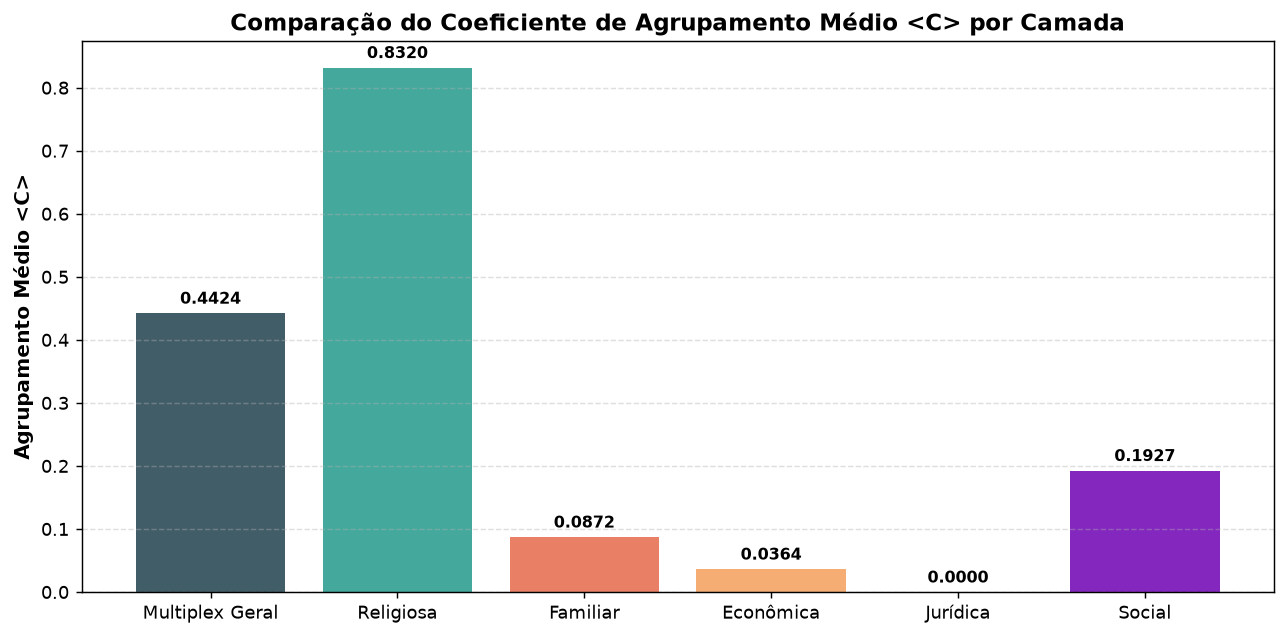

In [12]:
# COMPARAÇÃO MULTIDIMENSIONAL ENTRE AS 6 CAMADAS DA OTCVR
camadas = ['Religiosa', 'Familiar', 'Econômica', 'Jurídica', 'Social']
metricas_camadas = []

# Adiciona Multiplex
metricas_camadas.append({
    "Camada": "Multiplex Geral",
    "Nós": N_ativos,
    "Arestas": L_simples,
    "Densidade (%)": densidade * 100,
    "Grau Médio": k_medio,
    "Comp. Gigante (%)": pct_gigante,
    "Agrupamento <C>": ca_medio,
    "Distância <d>": avg_d,
    "Fiedler (λ2)": lambda_2
})

for cam in camadas:
    df_cam = df_edges[df_edges['camada'] == cam].copy()
    if len(df_cam) == 0:
        continue
    nos_cam = sorted(list(set(df_cam[src_col]).union(set(df_cam[tgt_col]))))
    g_cam = nx.Graph()
    for _, row in df_cam.iterrows():
        u, v = row[src_col], row[tgt_col]
        if u != v:
            g_cam.add_edge(u, v)
    
    n_c = g_cam.number_of_nodes()
    l_c = g_cam.number_of_edges()
    dens_c = nx.density(g_cam) * 100 if n_c > 1 else 0
    k_med_c = 2 * l_c / n_c if n_c > 0 else 0
    
    comps_c = sorted(nx.connected_components(g_cam), key=len, reverse=True)
    gc_c = g_cam.subgraph(comps_c[0]) if comps_c else g_cam
    pct_gc = (gc_c.number_of_nodes() / n_c) * 100 if n_c > 0 else 0
    c_med_c = nx.average_clustering(g_cam) if n_c > 1 else 0
    d_med_c = nx.average_shortest_path_length(gc_c) if gc_c.number_of_nodes() > 1 else 0
    
    # Fiedler
    if gc_c.number_of_nodes() > 2:
        L_c = nx.laplacian_matrix(gc_c).toarray()
        eig_c = scipy.linalg.eigvalsh(L_c)
        fied_c = eig_c[1]
    else:
        fied_c = 0.0
        
    metricas_camadas.append({
        "Camada": cam,
        "Nós": n_c,
        "Arestas": l_c,
        "Densidade (%)": dens_c,
        "Grau Médio": k_med_c,
        "Comp. Gigante (%)": pct_gc,
        "Agrupamento <C>": c_med_c,
        "Distância <d>": d_med_c,
        "Fiedler (λ2)": fied_c
    })

df_comp = pd.DataFrame(metricas_camadas)
print("=" * 70)
print("COMPARAÇÃO MULTIDIMENSIONAL ENTRE TODAS AS CAMADAS DA REDE")
print("=" * 70)
print(df_comp.to_string(index=False))

# Gráfico comparativo de Agrupamento Médio entre as Camadas
plt.figure(figsize=(10, 5))
cores = ["#264653", "#2A9D8F", "#E76F51", "#F4A261", "#E9C46A", "#7209B7"]
plt.bar(df_comp["Camada"], df_comp["Agrupamento <C>"], color=cores[:len(df_comp)], alpha=0.88)
plt.title("Comparação do Coeficiente de Agrupamento Médio <C> por Camada", fontsize=13, fontweight='bold')
plt.ylabel("Agrupamento Médio <C>", fontsize=11, fontweight='bold')
plt.grid(axis="y", linestyle="--", alpha=0.4)
for i, v in enumerate(df_comp["Agrupamento <C>"]):
    plt.text(i, v + 0.015, f"{v:.4f}", ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()


In [13]:
# QUADRO SÍNTESE FINAL CONSOLIDADO (TODAS AS ABAS 1, 2 E 3)
quadro_sintese = pd.DataFrame({
    "Aba / Domínio": [
        "1. Morfologia", "1. Morfologia", "1. Morfologia", "1. Morfologia",
        "1. Morfologia", "1. Morfologia", "1. Morfologia", "1. Morfologia",
        "1. Morfologia", "1. Morfologia",
        "2. Conectividade", "2. Conectividade", "2. Conectividade", "2. Conectividade",
        "2. Agrupamento", "2. Agrupamento",
        "3. Laplaciano", "3. Laplaciano", "3. Laplaciano"
    ],
    "Propriedade": [
        "Nós Ativos (N)", "Arestas Simples (L)", "Arestas Brutas (L_bruto)", "Capacidade K_N",
        "Densidade (D)", "Grau Médio <k>", "Grau Mediana", "Grau Máximo (Hub)",
        "Distância Média <d>", "Diâmetro Geodésico",
        "Componentes Conexos", "% Componente Gigante", "Pontos de Articulação", "Pontes (Bridges)",
        "Agrupamento Médio <C>", "Transitividade Global",
        "Dimensão do Laplaciano", "Menor Autovalor (λ1)", "Conectividade Algébrica (λ2 Fiedler)"
    ],
    "Valor Calculado": [
        f"{N_ativos:,}", f"{L_simples:,}", f"{L_bruto:,}", f"{L_completa:,}",
        f"{densidade:.6f} ({densidade*100:.3f}%)", f"{k_medio:.2f}", f"{k_mediana:.1f}", f"{k_max}",
        f"{avg_d:.4f}", f"{diametro}",
        f"{num_comps}", f"{pct_gigante:.2f}%", f"{len(art_indices)}", f"{len(bridges)}",
        f"{ca_medio:.4f} ({ca_medio*100:.2f}%)", f"{ca_global:.4f} ({ca_global*100:.2f}%)",
        f"{Laplacian.shape[0]} × {Laplacian.shape[1]}", f"{lambda_1:.6e}", f"{lambda_2:.6f}"
    ]
})

print("=" * 70)
print("QUADRO SÍNTESE CONSOLIDADO DAS PROPRIEDADES DE REDE OTCVR")
print("=" * 70)
print(quadro_sintese.to_string(index=False))
print("\n✓ Todos os cálculos das Abas 1, 2 e 3 foram executados com sucesso!")


QUADRO SÍNTESE CONSOLIDADO DAS PROPRIEDADES DE REDE OTCVR
   Aba / Domínio                          Propriedade   Valor Calculado
   1. Morfologia                       Nós Ativos (N)             1,321
   1. Morfologia                  Arestas Simples (L)            13,602
   1. Morfologia             Arestas Brutas (L_bruto)            14,734
   1. Morfologia                       Capacidade K_N           871,860
   1. Morfologia                        Densidade (D) 0.015601 (1.560%)
   1. Morfologia                       Grau Médio <k>             20.59
   1. Morfologia                         Grau Mediana               4.0
   1. Morfologia                    Grau Máximo (Hub)               506
   1. Morfologia                  Distância Média <d>            2.8035
   1. Morfologia                   Diâmetro Geodésico                 8
2. Conectividade                  Componentes Conexos               131
2. Conectividade                 % Componente Gigante            78.43%
2. Con